# Proyek UTS — Pengembangan Fitur (Kelompok AyapBesi)
**Student Academic Risk Prediction** — lanjutan dari `Student_Academic_Risk_MLP.ipynb`.

Notebook ini tidak melatih ulang model: ia memakai **MLP yang sama** (bobot hasil training Keras) untuk (1) membuktikan paritas engine inferensi ringan, (2) membangun & mengevaluasi **fitur unik #3** (deteksi input di luar domain) dan **#4** (probabilitas terkalibrasi + confidence threshold). Isi sel identik dengan `uts_analysis.py`. Tidak membutuhkan TensorFlow/GPU.

In [1]:
# jalankan dari root repo (di Colab: !git clone <repo> lalu %cd <repo>)
import os, sys
if os.path.basename(os.getcwd()) == 'notebook':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
print(os.getcwd())

/home/claude/proj


In [2]:
import json
import os
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold

from data_utils import SEED, load_split
from risk_engine import OODDetector, RiskEngine

BLUE, ORANGE, AQUA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
plt.rcParams.update({"figure.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad", "font.size": 9})
E = RiskEngine()
META = E.meta
R4 = lambda v: round(float(v), 4)

## 1. Data & split
Split stratified 60/20/20 (seed 42) **identik** dengan notebook utama, sehingga data testing yang sama tidak pernah dipakai untuk fitting parameter fitur baru.

In [3]:
(tr, ytr), (va, yva), (te, yte) = load_split()
Xtr, Xva, Xte = (E.preprocess(d[META["features"]]) for d in (tr, va, te))
p_tr, p_va, p_te = (E.predict_proba(X) for X in (Xtr, Xva, Xte))
out = {}

## 2. Paritas engine NumPy vs Keras
Bobot MLP dari `models/mlp_student_risk.keras` diekspor ke `models/mlp_weights.npz` (`tools/export_light_model.py`). Sel ini membuktikan preprocessing, metrik test, P(baseline), dan Integrated Gradients **identik** dengan hasil TensorFlow/Keras di `results/metrics.json`, lalu mengukur latensi inferensi.

In [4]:
import joblib
sk = joblib.load("models/preprocessor.joblib")
ref = json.load(open("results/metrics.json"))
yp = (p_te >= 0.5).astype(int)
att = np.array([E.integrated_gradients(x) for x in Xte])
out["parity"] = {
    "max_abs_diff_preprocessing": float(max(np.abs(sk.transform(d[META["features"]]).astype("float32") - X).max()
                                            for d, X in ((tr, Xtr), (va, Xva), (te, Xte)))),
    "test_metrics_engine": {"accuracy": R4(accuracy_score(yte, yp)), "precision": R4(precision_score(yte, yp)),
                            "recall": R4(recall_score(yte, yp)), "f1": R4(f1_score(yte, yp)),
                            "roc_auc": R4(roc_auc_score(yte, p_te)), "pr_auc": R4(average_precision_score(yte, p_te))},
    "test_metrics_keras": {k: ref["main_metrics"]["test"][k] for k in ("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc")},
    "p_baseline_engine": R4(E.predict_proba(E.baseline[None])[0]), "p_baseline_keras": ref["ig"]["p_baseline"],
    "ig_completeness_engine": float(np.abs(att.sum(1) - (p_te - E.predict_proba(E.baseline[None])[0])).mean()),
    "ig_global_top5_engine": pd.DataFrame([E.group_attributions(a) for a in att]).abs().mean()
                              .sort_values(ascending=False).head(5).round(4).to_dict(),
}
assert out["parity"]["test_metrics_engine"] == out["parity"]["test_metrics_keras"], "paritas gagal"

# latensi inferensi (CPU)
row = te[META["features"]].iloc[[0]]
t0 = time.perf_counter(); [E.predict_df(row) for _ in range(200)]; t_pred = (time.perf_counter() - t0) / 200
t0 = time.perf_counter(); [E.integrated_gradients(Xte[0]) for _ in range(50)]; t_ig = (time.perf_counter() - t0) / 50
full = pd.concat([tr, va, te])[META["features"]]
t0 = time.perf_counter(); E.predict_df(full); t_batch = time.perf_counter() - t0
out["engine"] = {"latency_predict_ms": round(t_pred * 1000, 3), "latency_ig_ms": round(t_ig * 1000, 2),
                 "batch_649_ms": round(t_batch * 1000, 2),
                 "size_keras_kb": round(os.path.getsize("models/mlp_student_risk.keras") / 1024, 1),
                 "size_npz_kb": round(os.path.getsize("models/mlp_weights.npz") / 1024, 1),
                 "size_prep_joblib_kb": round(os.path.getsize("models/preprocessor.joblib") / 1024, 1),
                 "size_prep_json_kb": round(os.path.getsize("models/preprocess_params.json") / 1024, 1)}

In [5]:
pd.DataFrame({"engine NumPy": out["parity"]["test_metrics_engine"], "Keras (results/metrics.json)": out["parity"]["test_metrics_keras"]})

,engine NumPy,Keras (results/metrics.json)
accuracy,0.8615,0.8615
precision,0.5357,0.5357
recall,0.7500,0.7500
f1,0.6250,0.6250
roc_auc,0.9182,0.9182
pr_auc,0.7026,0.7026


## 3. Fitur unik #3 — Deteksi input di luar domain (OOD)
Lapis 1: validasi aturan (rentang & kategori). Lapis 2: jarak Mahalanobis kuadrat di ruang 45 dimensi dengan kovarians **Ledoit-Wolf** (fit pada training). Ambang = persentil ke-99 skor **out-of-fold** (5-fold) training agar tidak bias optimistis. Diuji pada data asli dan 5 skenario input janggal.

In [6]:
lw = LedoitWolf().fit(Xtr)
oof = np.zeros(len(Xtr))  # skor out-of-fold agar ambang tidak bias optimistis
for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xtr, ytr):
    f = LedoitWolf().fit(Xtr[a]); D = Xtr[b] - f.location_
    oof[b] = np.einsum("ij,jk,ik->i", D, f.precision_, D)
threshold = float(np.percentile(oof, 99))
np.savez("models/ood_detector.npz", mean=lw.location_, precision=lw.precision_, threshold=threshold, train_scores=oof)
ood = OODDetector(E)

rng = np.random.default_rng(SEED)
base = te[META["features"]].reset_index(drop=True)
n = len(base); R, CH = META["valid_ranges"], META["choices"]
S = {}
S["Profil acak (nilai sah, kombinasi acak)"] = pd.DataFrame(
    {**{c: rng.integers(R[c][0], R[c][1] + 1, n) for c in META["numeric"]},
     **{c: rng.choice(CH[c], n) for c in META["binary"] + META["nominal"]}})[META["features"]]
s = base.copy(); s["absences"] = rng.integers(40, 94, n); S["Absensi ekstrem (40-93)"] = s
s = base.copy(); hi = rng.random(n) < 0.5
s["G1"] = np.where(hi, rng.integers(16, 21, n), rng.integers(0, 5, n))
s["G2"] = np.where(hi, rng.integers(0, 5, n), rng.integers(16, 21, n)); S["Lonjakan nilai G1-G2 (>=12 poin)"] = s
s = base.copy(); s["G1"] = rng.integers(50, 101, n); s["G2"] = rng.integers(50, 101, n); S["Salah skala nilai (0-100)"] = s
s = base.copy()
for c in META["features"]:
    s[c] = rng.permutation(s[c].values)
S["Kolom diacak antarsiswa"] = s


def ood_eval(df):
    X = E.preprocess(df); chk = ood.check_frame(df, X); p = E.predict_proba(X)
    return {"n": len(df), "rule_rate": R4((chk.status_input == "DITOLAK").mean()),
            "mahal_rate": R4((chk.ood_score > threshold).mean()),
            "flag_rate": R4((chk.status_input != "OK").mean()),
            "median_score": round(float(np.median(chk.ood_score)), 1),
            "confident_rate": R4(((p > 0.9) | (p < 0.1)).mean()), "mean_p": R4(p.mean())}, chk.ood_score


ood_res, scores = {}, {}
for nm, d in [("Training (out-of-fold)", None), ("Validation (asli)", va[META["features"]]),
              ("Testing (asli)", te[META["features"]])] + list(S.items()):
    if d is None:
        ood_res[nm] = {"n": len(oof), "rule_rate": 0.0, "mahal_rate": R4((oof > threshold).mean()),
                       "flag_rate": R4((oof > threshold).mean()), "median_score": round(float(np.median(oof)), 1),
                       "confident_rate": R4(((p_tr > .9) | (p_tr < .1)).mean()), "mean_p": R4(p_tr.mean())}
        scores[nm] = oof
    else:
        ood_res[nm], scores[nm] = ood_eval(d)
out["ood"] = {"method": "Ledoit-Wolf Mahalanobis (45 dim) + validasi aturan", "threshold": round(threshold, 2),
              "threshold_rule": "persentil ke-99 skor out-of-fold (5-fold) data training",
              "shrinkage": R4(lw.shrinkage_), "scenarios": ood_res}

fig, ax = plt.subplots(figsize=(8.6, 4.2))
names = list(scores)[::-1]
for i, nm in enumerate(names):
    v = np.log10(np.maximum(scores[nm], 1e-1))
    col = BLUE if i >= len(names) - 3 else ORANGE
    ax.scatter(v, i + rng.uniform(-0.18, 0.18, len(v)), s=8, alpha=0.45, color=col, linewidths=0)
    ax.text(3.95, i, f"{ood_res[nm]['flag_rate'] * 100:.1f}%", va="center", ha="right", fontsize=8, color="#0b0b0b")
ax.axvline(np.log10(threshold), color=RED, lw=1.5, ls="--")
ax.text(np.log10(threshold) + 0.04, -0.75, f"ambang = {threshold:.1f}", color=RED, fontsize=8)
ax.set_yticks(range(len(names)), names); ax.set_xlim(0.9, 4.0); ax.set_ylim(-1.1, len(names) - 0.5)
ax.set_xlabel("log10 jarak Mahalanobis² (ruang fitur 45 dimensi)")
ax.set_title("Fitur unik #3 — skor OOD per kelompok data\nbiru = data asli, oranye = input janggal; angka di kanan = % input yang ditandai", fontsize=9)
fig.tight_layout(); fig.savefig("figures/16_ood_skor_mahalanobis.png"); plt.close(fig)

In [7]:
pd.DataFrame(out["ood"]["scenarios"]).T

,n,rule_rate,mahal_rate,flag_rate,median_score,confident_rate,mean_p
Training (out-of-fold),389.0,0.0,0.0103,0.0103,38.6,0.0283,0.3321
Validation (asli),130.0,0.0,0.0000,0.0000,38.1,0.0385,0.3252
Testing (asli),130.0,0.0,0.0077,0.0077,38.7,0.0462,0.3399
"Profil acak (nilai sah, kombinasi acak)",130.0,0.0,1.0000,1.0000,256.0,0.2462,0.3516
Absensi ekstrem (40-93),130.0,0.0,1.0000,1.0000,265.6,0.3923,0.1775
Lonjakan nilai G1-G2 (>=12 poin),130.0,0.0,1.0000,1.0000,148.9,0.0000,0.4059
Salah skala nilai (0-100),130.0,1.0,1.0000,1.0000,1183.6,1.0000,0.0000
Kolom diacak antarsiswa,130.0,0.0,0.0538,0.0538,53.4,0.0154,0.3263


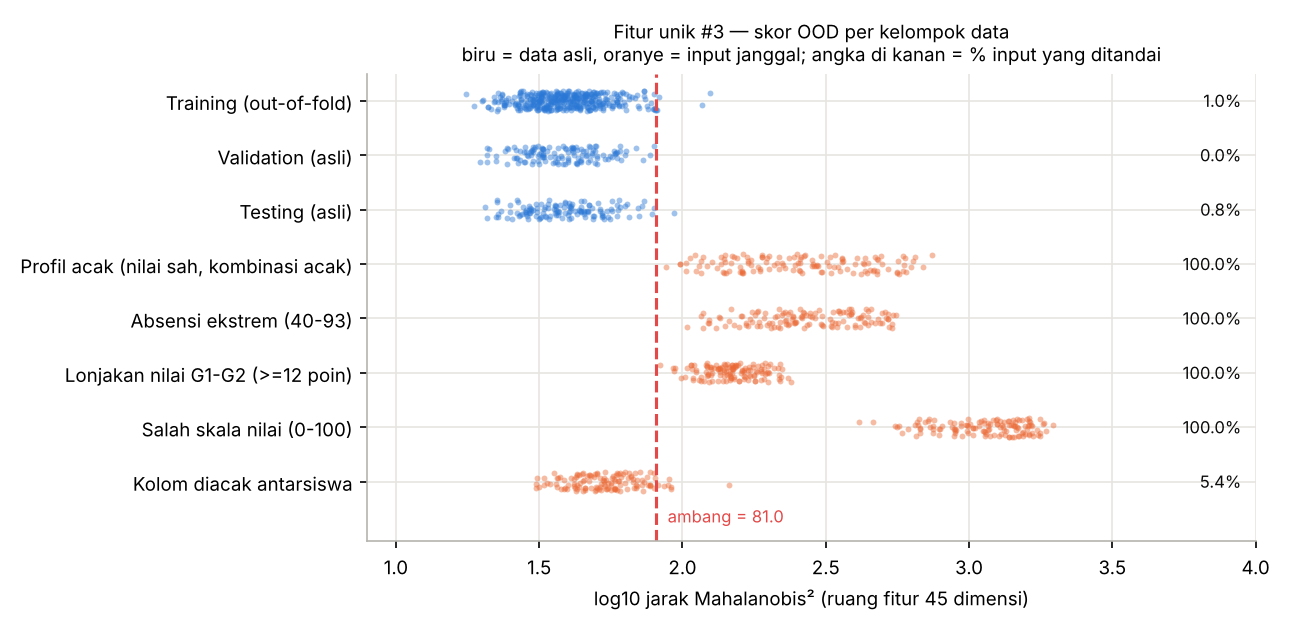

In [8]:
from IPython.display import Image, display
display(Image(filename='figures/16_ood_skor_mahalanobis.png'))

## 4. Fitur unik #4 — Probabilitas terkalibrasi + confidence threshold
Focal loss menekan kontribusi sampel mudah sehingga probabilitas cenderung tidak terkalibrasi. **Temperature scaling** (1 parameter, fit NLL pada validation) memperbaiki kalibrasi tanpa mengubah prediksi pada ambang 0,5. **Confidence threshold τ** dipilih pada validation: τ terkecil dengan akurasi prediksi *yakin* ≥ 95%. MC Dropout dievaluasi sebagai pembanding.

In [9]:
logit = lambda q: np.log(np.clip(q, 1e-7, 1 - 1e-7) / (1 - np.clip(q, 1e-7, 1 - 1e-7)))
sig = lambda z: 1 / (1 + np.exp(-z))


def nll(T, y, p):
    q = np.clip(sig(logit(p) / T), 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))


T = float(minimize_scalar(nll, bounds=(0.05, 5), method="bounded", args=(yva, p_va)).x)
cal = lambda p: sig(logit(p) / T)
c_va, c_te = cal(p_va), cal(p_te)


def ece(y, p, bins=10):
    e, edges = 0.0, np.linspace(0, 1, bins + 1)
    for i in range(bins):
        m = (p >= edges[i]) & ((p < edges[i + 1]) if i < bins - 1 else (p <= 1))
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e


taus = [0.6, 0.7, 0.75, 0.8, 0.85, 0.9]
def sel(y, p, tau):
    conf = np.maximum(p, 1 - p); k = conf >= tau; err = (p >= 0.5) != y
    return {"tau": tau, "coverage": R4(k.mean()), "acc_confident": R4(accuracy_score(y[k], p[k] >= .5)),
            "n_flagged": int((~k).sum()), "err_flagged": int(err[~k].sum()), "err_total": int(err.sum()),
            "acc_flagged": R4(accuracy_score(y[~k], p[~k] >= .5)) if (~k).any() else None}
grid_val = [sel(yva, c_va, t) for t in taus]
tau = next(g["tau"] for g in grid_val if g["acc_confident"] >= 0.95)  # τ terkecil dgn akurasi yakin ≥ 95% di VALIDATION
grid_test = [sel(yte, c_te, t) for t in taus]
cut_low = float(cal(np.array([META["risk_levels"][0][0]]))[0])  # batas Rendah/Sedang lama (0.30) dalam skala terkalibrasi

lv = lambda q: np.where(q < cut_low, "Rendah", np.where(q < 0.5, "Sedang", "Tinggi"))
L = lv(c_te)
levels = [{"tingkat": l, "n": int((L == l).sum()), "berisiko_aktual": int(yte[L == l].sum()),
           "pct_berisiko_aktual": round(float(yte[L == l].mean() * 100), 1), "mean_p_raw": R4(p_te[L == l].mean()),
           "mean_p_cal": R4(c_te[L == l].mean())} for l in ("Rendah", "Sedang", "Tinggi")]

# pembanding: MC Dropout sebagai estimator ketidakpastian alternatif
mc_mean, mc_sd, _ = E.mc_dropout(Xte, T=100, seed=0)
err = (p_te >= 0.5) != yte
k80 = int(round(0.8 * len(yte)))
def acc_at(order):
    idx = order[:k80]; return R4(accuracy_score(yte[idx], p_te[idx] >= .5))
out["calibration"] = {
    "temperature": R4(T), "fit_on": "validation (NLL)", "confidence_threshold": tau,
    "tau_rule": "tau terkecil dengan akurasi prediksi 'yakin' >= 95% pada data validation",
    "ece_test_before": R4(ece(yte, p_te)), "ece_test_after": R4(ece(yte, c_te)),
    "brier_test_before": R4(brier_score_loss(yte, p_te)), "brier_test_after": R4(brier_score_loss(yte, c_te)),
    "nll_test_before": R4(nll(1.0, yte, p_te)), "nll_test_after": R4(nll(T, yte, p_te)),
    "ece_val_before": R4(ece(yva, p_va)), "ece_val_after": R4(ece(yva, c_va)),
    "predictions_unchanged": bool(((c_te >= .5) == (p_te >= .5)).all()),
    "risk_cut_low_calibrated": R4(cut_low), "risk_levels_test": levels,
    "grid_val": grid_val, "grid_test": grid_test,
    "uncertainty_compare": {
        "auroc_err_margin_calibrated": R4(roc_auc_score(err, -np.abs(c_te - .5))),
        "auroc_err_mc_dropout_sd": R4(roc_auc_score(err, mc_sd)),
        "acc_at_80pct_margin": acc_at(np.argsort(-np.abs(c_te - .5))),
        "acc_at_80pct_mc_dropout": acc_at(np.argsort(mc_sd)),
        "acc_at_100pct": R4(accuracy_score(yte, p_te >= .5)),
        "mc_dropout_T": 100, "mc_mean_sd_correct": R4(mc_sd[~err].mean()), "mc_mean_sd_wrong": R4(mc_sd[err].mean()),
        "mc_test_accuracy": R4(accuracy_score(yte, mc_mean >= .5)), "mc_test_roc_auc": R4(roc_auc_score(yte, mc_mean))},
}
json.dump({"temperature": T, "confidence_threshold": tau, "risk_levels_calibrated": [[cut_low, "Rendah"], [0.5, "Sedang"], [1.01, "Tinggi"]],
           "note": "probabilitas terkalibrasi = sigmoid(logit(p)/temperature); di-fit pada data validation"},
          open("models/calibration.json", "w"), indent=1)

# figur 17: reliability diagram
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.6))
edges = np.linspace(0, 1, 11)
for ax, (nm, q, col) in zip(axs, [("Sebelum kalibrasi", p_te, ORANGE), (f"Sesudah temperature scaling (T = {T:.3f})", c_te, BLUE)]):
    xs, ys, ns = [], [], []
    for i in range(10):
        m = (q >= edges[i]) & ((q < edges[i + 1]) if i < 9 else (q <= 1))
        if m.any():
            xs.append(q[m].mean()); ys.append(yte[m].mean()); ns.append(m.sum())
    ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="kalibrasi sempurna")
    ax.plot(xs, ys, "-o", color=col, lw=2, ms=5, label="model")
    for x_, y_, n_ in zip(xs, ys, ns):
        ax.annotate(f"n={n_}", (x_, y_), textcoords="offset points", xytext=(4, -10), fontsize=7, color="#52514e")
    ax.set_xlim(0, 1); ax.set_ylim(-0.02, 1.02); ax.set_xlabel("probabilitas prediksi (rata-rata per bin)")
    ax.set_ylabel("proporsi berisiko aktual"); ax.legend(loc="upper left", fontsize=7, frameon=False)
    ax.set_title(f"{nm}\nECE = {ece(yte, q):.3f} · Brier = {brier_score_loss(yte, q):.3f}", fontsize=9)
fig.suptitle("Fitur unik #4 — reliability diagram pada data testing", fontsize=10)
fig.tight_layout(); fig.savefig("figures/17_kalibrasi_reliability.png"); plt.close(fig)

# figur 18: coverage vs akurasi (confidence threshold)
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.4))
for nm, g, col in (("validation", grid_val, ORANGE), ("testing", grid_test, BLUE)):
    axs[0].plot([x["coverage"] for x in g], [x["acc_confident"] for x in g], "-o", color=col, lw=2, ms=4, label=nm)
    for x in g:
        if x["tau"] == tau:
            axs[0].annotate(f"τ={tau}", (x["coverage"], x["acc_confident"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
axs[0].axhline(accuracy_score(yte, p_te >= .5), color=GRAY, ls="--", lw=1)
axs[0].text(0.665, accuracy_score(yte, p_te >= .5) + 0.004, "akurasi tanpa threshold (test)", fontsize=7, color="#52514e")
axs[0].set_xlabel("coverage (porsi prediksi berstatus 'yakin')"); axs[0].set_ylabel("akurasi pada prediksi 'yakin'")
axs[0].legend(frameon=False, fontsize=8); axs[0].set_title("Trade-off coverage vs akurasi (τ = 0.6 … 0.9)", fontsize=9)
gt = next(x for x in grid_test if x["tau"] == tau)
cats = ["Yakin", "Perlu verifikasi"]
right = [gt["coverage"] * len(yte) - (gt["err_total"] - gt["err_flagged"]), gt["n_flagged"] - gt["err_flagged"]]
wrong = [gt["err_total"] - gt["err_flagged"], gt["err_flagged"]]
axs[1].bar(cats, right, color=BLUE, width=0.55, label="prediksi benar", edgecolor="white", linewidth=2)
axs[1].bar(cats, wrong, bottom=right, color=RED, width=0.55, label="prediksi salah", edgecolor="white", linewidth=2)
for i in range(2):
    axs[1].text(i, right[i] + wrong[i] + 1.5, f"{int(wrong[i])} salah dari {int(right[i] + wrong[i])}", ha="center", fontsize=8)
axs[1].set_ylabel("jumlah siswa (test)"); axs[1].legend(frameon=False, fontsize=8)
axs[1].set_title(f"Status keyakinan pada data testing (τ = {tau})", fontsize=9); axs[1].set_ylim(0, 120)
fig.tight_layout(); fig.savefig("figures/18_confidence_threshold.png"); plt.close(fig)

In [10]:
pd.DataFrame(out["calibration"]["grid_test"])

,tau,coverage,acc_confident,n_flagged,err_flagged,err_total,acc_flagged
0,0.60,0.8923,0.8966,14,6,18,0.5714
1,0.70,0.8385,0.9174,21,9,18,0.5714
2,0.75,0.8000,0.9327,26,11,18,0.5769
3,0.80,0.7692,0.9300,30,11,18,0.6333
4,0.85,0.7077,0.9565,38,14,18,0.6316
5,0.90,0.6615,0.9651,44,15,18,0.6591


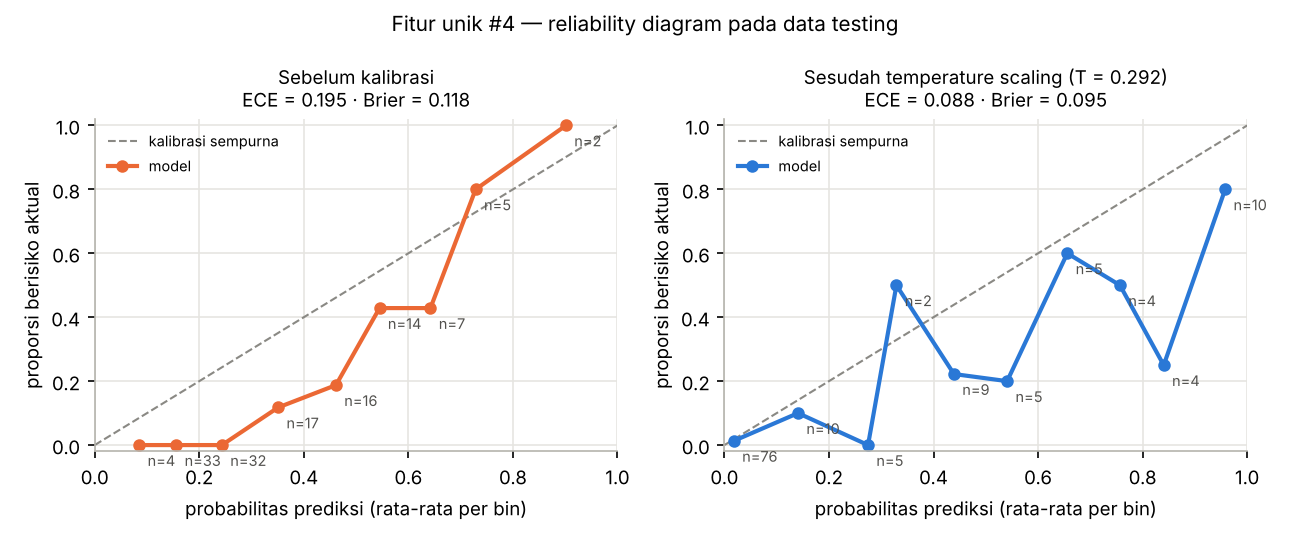

In [11]:
from IPython.display import Image, display
display(Image(filename='figures/17_kalibrasi_reliability.png'))

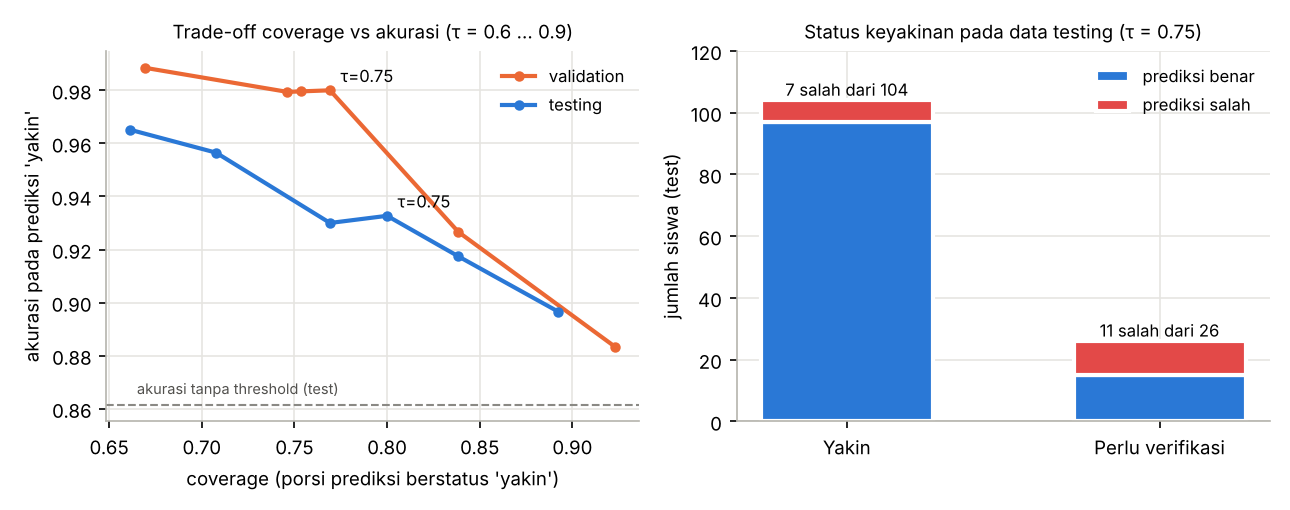

In [12]:
from IPython.display import Image, display
display(Image(filename='figures/18_confidence_threshold.png'))

## 5. Diagram arsitektur sistem & deployment

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 40)
def box(x, y, w, h, t, c):
    ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.2", fc=c, ec="#52514e", lw=0.8))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=7.2)
def arr(x1, y1, x2, y2):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color="#52514e", lw=1))
LB, LO, LG = "#dbe9fa", "#fde3d6", "#eeeeea"
box(1, 26, 17, 10, "Notebook Colab\n(TensorFlow/Keras)\nlatih MLP + focal loss", LG)
box(23, 26, 17, 10, "mlp_student_risk.keras\npreprocessor.joblib", LG)
box(45, 26, 19, 10, "tools/export_light_model.py\n→ mlp_weights.npz\n→ preprocess_params.json", LB)
box(69, 26, 30, 10, "uts_analysis.py\n→ ood_detector.npz (fitur #3)\n→ calibration.json (fitur #4)", LB)
arr(18.8, 31, 22.2, 31); arr(40.8, 31, 44.2, 31); arr(64.8, 31, 68.2, 31)
box(1, 3, 22, 14, "Pengguna (guru/wali kelas)\nform 1 siswa atau CSV 1 kelas", LO)
box(29, 3, 40, 14, "app.py (Gradio) + risk_engine.py (NumPy)\n1 validasi input & OOD  →  2 MLP  →  3 kalibrasi\n→ 4 confidence threshold  →  5 Integrated Gradients\n→ tingkat risiko + faktor + rekomendasi", LB)
box(75, 3, 24, 14, "GitHub (source code)\n↓ git push\nHugging Face Spaces\n(Gradio SDK, CPU basic)", LG)
arr(23.8, 10, 28.2, 10); arr(69.8, 10, 74.2, 10); arr(84, 25, 84, 17.8)
ax.set_title("Arsitektur sistem dan alur deployment", fontsize=10)
fig.tight_layout(); fig.savefig("figures/19_arsitektur_deployment.png"); plt.close(fig)

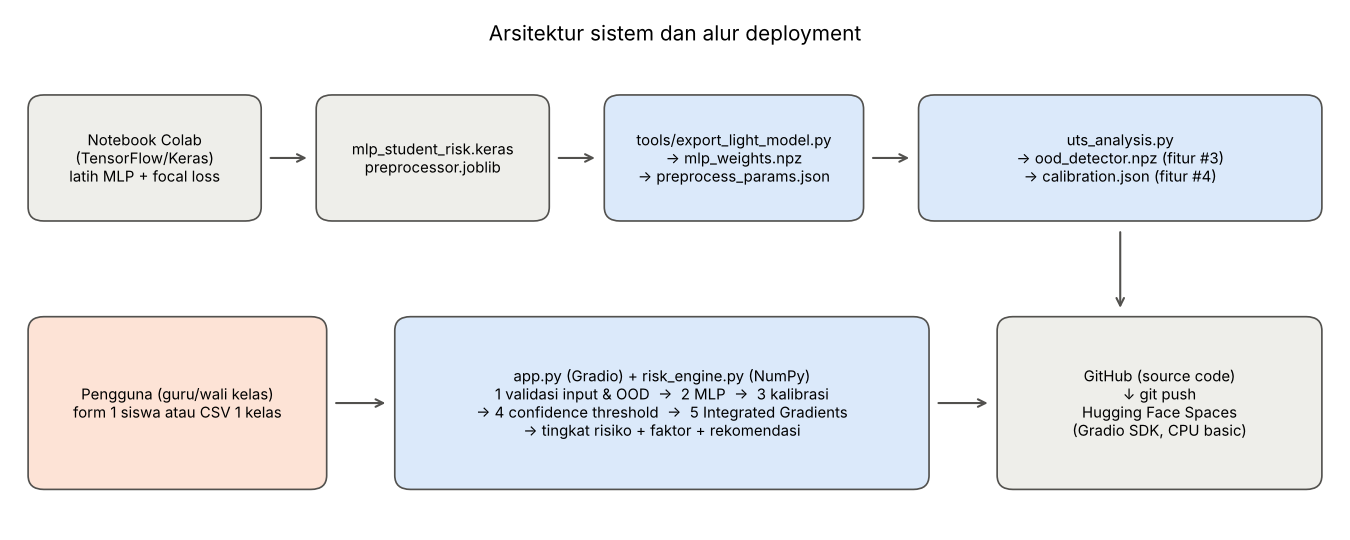

In [14]:
from IPython.display import Image, display
display(Image(filename='figures/19_arsitektur_deployment.png'))

## 6. Data contoh untuk demo & penyimpanan hasil
Menulis `data/contoh_demo.csv` (TP, TN, FP, FN, dan dua input di luar domain) serta `data/kelas_uji.csv`, lalu menyimpan semua angka ke `results/uts_metrics.json`.

In [15]:
tt = te.reset_index(drop=True).copy()
tt["prob_model"] = p_te; tt["aktual"] = yte; tt["prediksi"] = (p_te >= .5).astype(int)
pick = []
def first(mask, key, asc, ket):
    r = tt[mask].sort_values(key, ascending=asc).iloc[0].copy(); r["keterangan"] = ket; pick.append(r)
first((tt.aktual == 1) & (tt.prediksi == 1), "prob_model", False, "Benar - siswa berisiko terdeteksi (TP)")
first((tt.aktual == 0) & (tt.prediksi == 0), "prob_model", True, "Benar - siswa aman (TN)")
first((tt.aktual == 0) & (tt.prediksi == 1), "prob_model", False, "Salah - alarm palsu (FP), G3 aktual >= 10")
first((tt.aktual == 1) & (tt.prediksi == 0), "prob_model", False, "Salah - terlewat (FN), G3 aktual < 10")
r = tt.iloc[0].copy(); r["G1"], r["G2"] = 85, 90; r["keterangan"] = "Di luar domain - nilai ditulis skala 0-100 (DITOLAK)"; pick.append(r)
r = tt.iloc[1].copy(); r["absences"] = 75; r["keterangan"] = "Di luar domain - absensi 75 kali (PERINGATAN)"; pick.append(r)
demo = pd.DataFrame(pick)[["keterangan"] + META["features"] + ["G3"]]
demo.to_csv("data/contoh_demo.csv", index=False)
te[META["features"] + ["G3"]].to_csv("data/kelas_uji.csv", index=False)
dd = demo.reset_index(drop=True); Xd = E.preprocess(dd[META["features"]]); chk = ood.check_frame(dd[META["features"]], Xd)
out["demo_cases"] = [{"keterangan": k, "G1": int(g1), "G2": int(g2), "G3": int(g3), "p_raw": R4(p), "p_cal": R4(cal(np.array([p]))[0]),
                      "status_input": s} for k, g1, g2, g3, p, s in zip(dd.keterangan, dd.G1, dd.G2, dd.G3, E.predict_proba(Xd), chk.status_input)]

json.dump(out, open("results/uts_metrics.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps({k: out[k] for k in ("parity", "engine")}, indent=1, ensure_ascii=False))
print("OOD threshold", out["ood"]["threshold"]); print(pd.DataFrame(out["ood"]["scenarios"]).T)
c = out["calibration"]; print({k: c[k] for k in c if not k.startswith("grid") and k != "risk_levels_test"})
print(pd.DataFrame(c["grid_test"])); print(pd.DataFrame(c["risk_levels_test"])); print(pd.DataFrame(out["demo_cases"]))

{
 "parity": {
  "max_abs_diff_preprocessing": 0.0,
  "test_metrics_engine": {
   "accuracy": 0.8615,
   "precision": 0.5357,
   "recall": 0.75,
   "f1": 0.625,
   "roc_auc": 0.9182,
   "pr_auc": 0.7026
  },
  "test_metrics_keras": {
   "accuracy": 0.8615,
   "precision": 0.5357,
   "recall": 0.75,
   "f1": 0.625,
   "roc_auc": 0.9182,
   "pr_auc": 0.7026
  },
  "p_baseline_engine": 0.2803,
  "p_baseline_keras": 0.2803,
  "ig_completeness_engine": 0.0005958104156889021,
  "ig_global_top5_engine": {
   "G2": 0.0866,
   "G1": 0.0661,
   "school": 0.0421,
   "failures": 0.0233,
   "absences": 0.0209
  }
 },
 "engine": {
  "latency_predict_ms": 3.495,
  "latency_ig_ms": 0.09,
  "batch_649_ms": 5.74,
  "size_keras_kb": 112.5,
  "size_npz_kb": 24.7,
  "size_prep_joblib_kb": 7.6,
  "size_prep_json_kb": 2.9
 }
}
OOD threshold 80.97
                                             n  ...  mean_p
Training (out-of-fold)                   389.0  ...  0.3321
Validation (asli)                        130

In [16]:
pd.DataFrame(out["demo_cases"])

,keterangan,G1,G2,G3,p_raw,p_cal,status_input
0,Benar - siswa berisiko terdeteksi (TP),7,0,0,0.9015,0.9995,OK
1,Benar - siswa aman (TN),18,19,19,0.0668,0.0001,OK
2,"Salah - alarm palsu (FP), G3 aktual >= 10",6,9,11,0.7110,0.9563,OK
3,"Salah - terlewat (FN), G3 aktual < 10",7,8,8,0.4774,0.4231,OK
4,Di luar domain - nilai ditulis skala 0-100 (DITOLAK),85,90,12,0.0000,0.0000,DITOLAK
5,Di luar domain - absensi 75 kali (PERINGATAN),13,12,12,0.1352,0.0017,DI LUAR DOMAIN


## Ringkasan
Semua angka di atas tersimpan di `results/uts_metrics.json` dan dikutip apa adanya di laporan UTS (Bab 5e dan 6d).